In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
PROJECT_PATH = '/content/drive/MyDrive/project'

In [ ]:
import requests
from PIL import Image, ImageDraw, ImageFont
import os

# 下载中文字体（以思源黑体为例）
def download_chinese_font():
    font_url = "https://github.com/adobe-fonts/source-han-sans/raw/release/OTF/SimplifiedChinese/SourceHanSansSC-Regular.otf"
    font_path = "SourceHanSansSC-Regular.otf"

    if not os.path.exists(font_path):
        response = requests.get(font_url)
        with open(font_path, 'wb') as f:
            f.write(response.content)

    return font_path

# 使用下载的字体
font_path = download_chinese_font()
font = ImageFont.truetype(font_path, 40)

开始特征可视化...
模型权重已从 /content/drive/MyDrive/project/user_data/model_data/single_digit_best.pth 加载

1. 加载实际图像集...
找到 40000 张图像文件
成功加载 10 张真实图像

可视化第一张图像的特征激活...


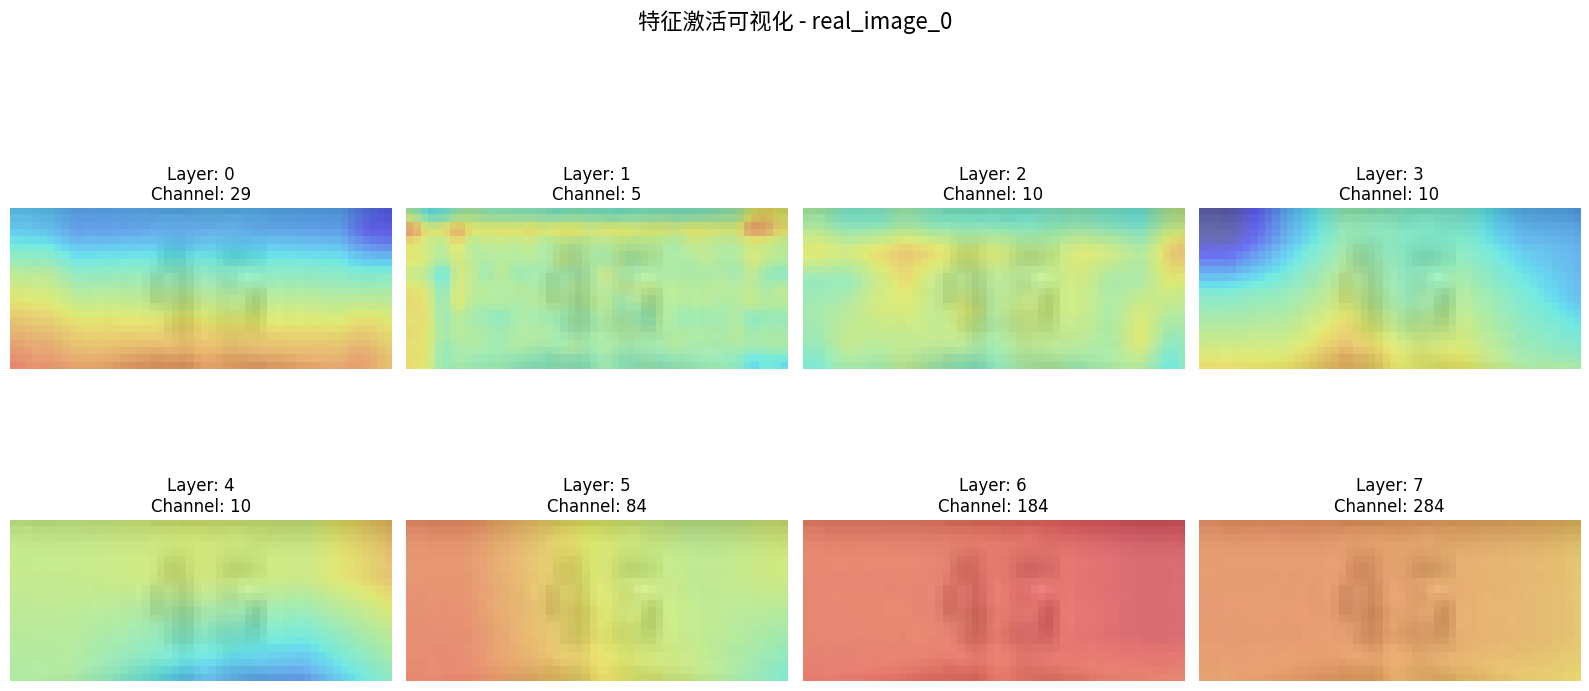


可视化特征图网格...


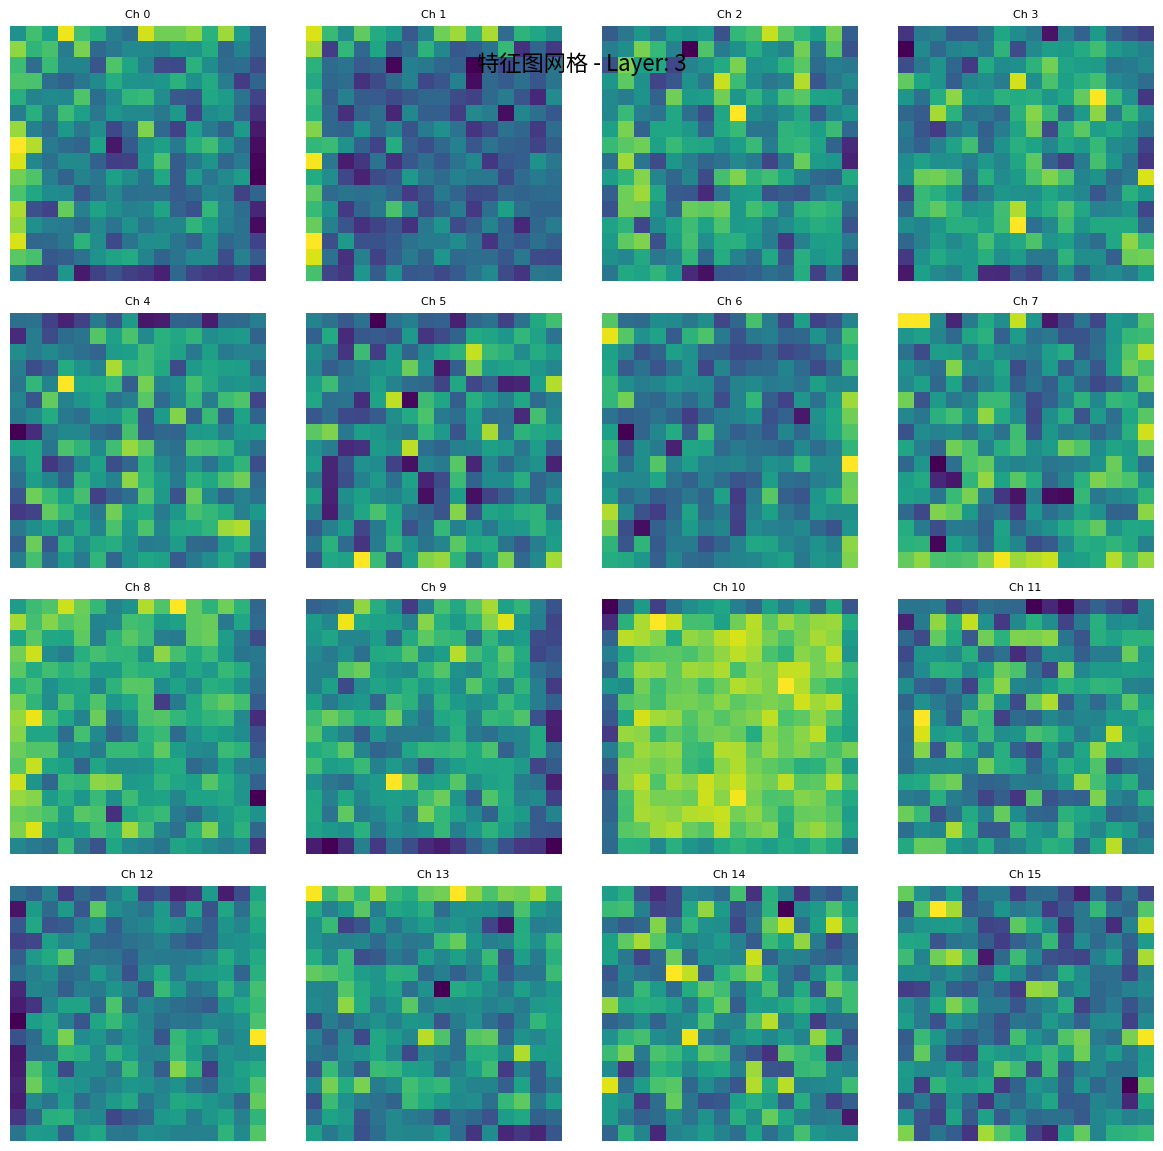


可视化卷积核...


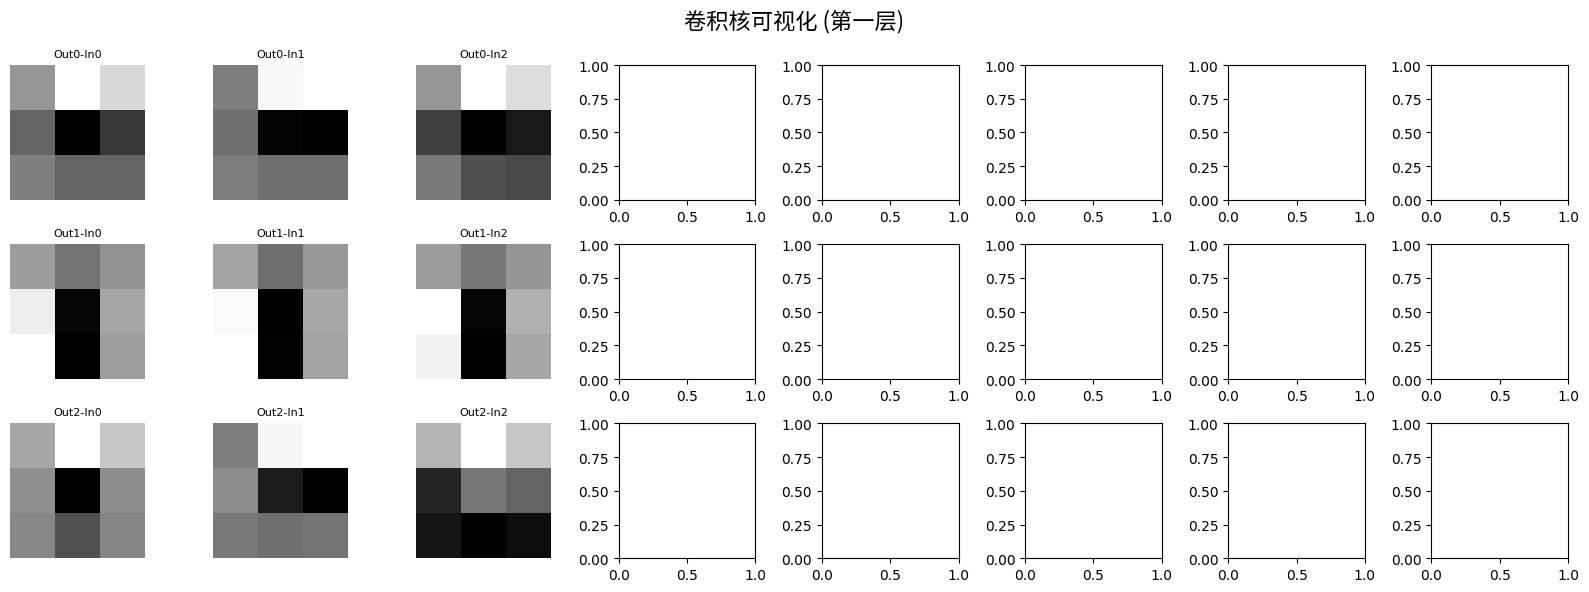


可视化Grad-CAM...


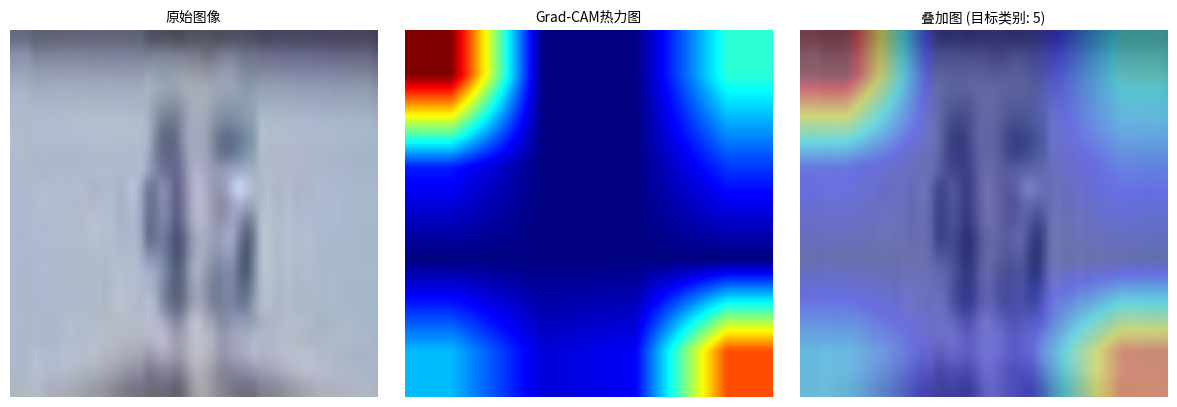


可视化注意力模式...


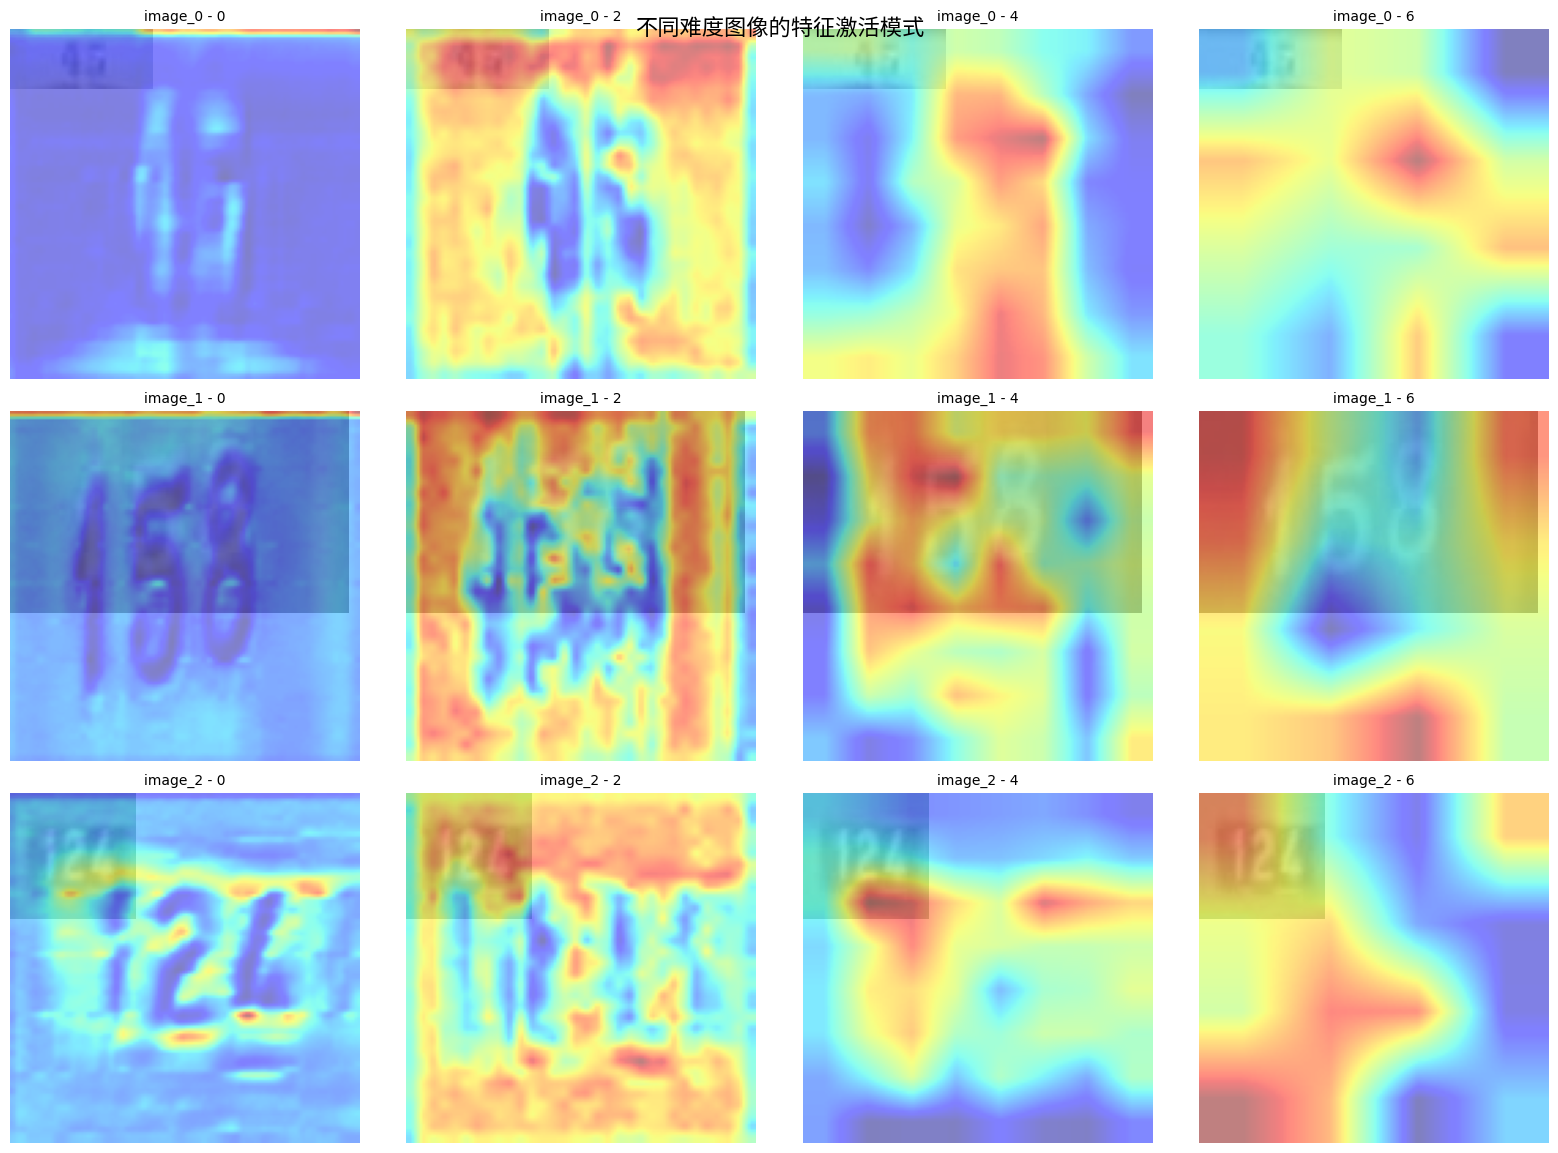


分析层统计信息...


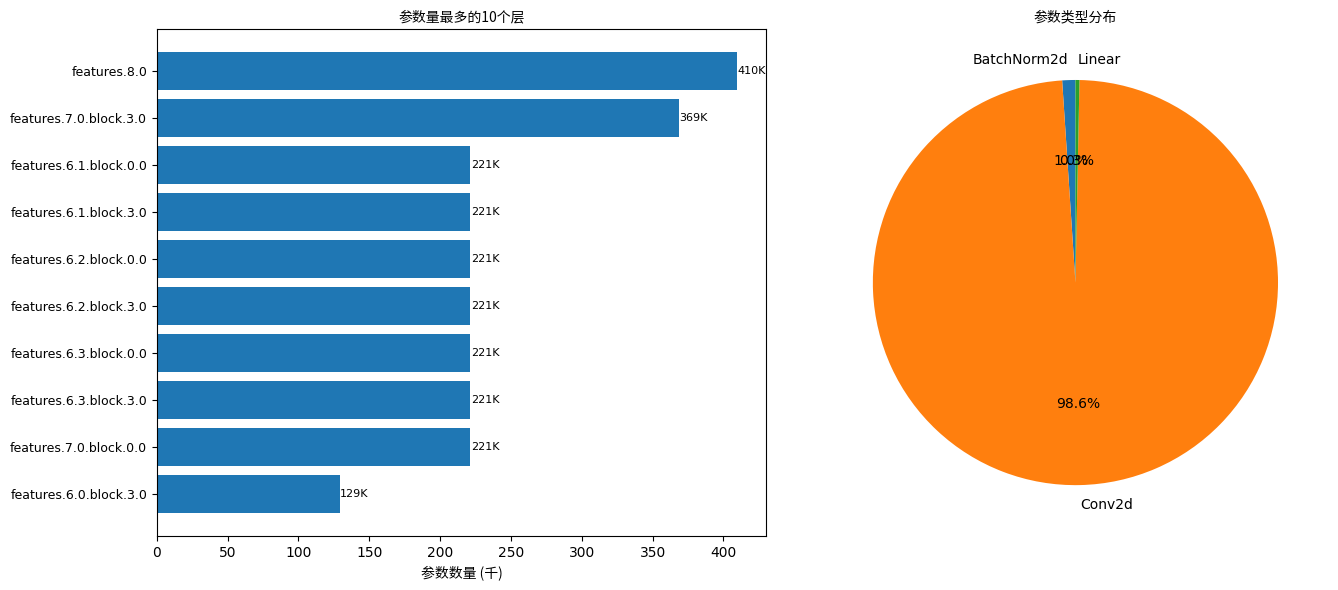


层统计信息:
                    name        type  params  params_percent                        info
            features.0.0      Conv2d     864      100.000000      in=3, out=32, k=(3, 3)
            features.0.1 BatchNorm2d      64        6.896552                 features=32
  features.1.0.block.0.0      Conv2d     288       23.684211     in=32, out=32, k=(3, 3)
  features.1.0.block.0.1 BatchNorm2d      64        5.000000                 features=32
features.1.0.block.1.fc1      Conv2d     264       17.098446      in=32, out=8, k=(1, 1)
features.1.0.block.1.fc2      Conv2d     288       15.720524      in=8, out=32, k=(1, 1)
  features.1.0.block.2.0      Conv2d     512       21.843003     in=32, out=16, k=(1, 1)
  features.1.0.block.2.1 BatchNorm2d      32        1.346801                 features=16
  features.2.0.block.0.0      Conv2d    1536       39.263804     in=16, out=96, k=(1, 1)
  features.2.0.block.0.1 BatchNorm2d     192        4.678363                 features=96
  features.2.

In [ ]:
import torch
import torch.nn as nn
from torchvision import models, transforms
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from PIL import Image
import cv2
import warnings
import pandas as pd # Add this import
warnings.filterwarnings('ignore')

class FeatureVisualizer:
    def __init__(self, device='cuda' if torch.cuda.is_available() else 'cpu'):
        self.device = torch.device(device)
        self.transform = transforms.Compose([
            transforms.Resize((128, 128)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])

        # 加载模型
        self.model = self.load_efficientnet()
        self.activations = {}
        self.hooks = []

    def load_efficientnet(self):
        """加载EfficientNet-B0模型"""
        model = models.efficientnet_b0(weights=None)
        model.classifier[1] = nn.Linear(1280, 10)

        # 加载预训练权重
        model_path = "/content/drive/MyDrive/project/user_data/model_data/single_digit_best.pth"
        try:
            model.load_state_dict(torch.load(model_path, map_location=self.device))
            print(f"模型权重已从 {model_path} 加载")
        except:
            print("使用随机初始化的模型权重")

        model.to(self.device)
        model.eval()
        return model

    def register_hooks(self):
        """注册钩子以获取中间层激活"""
        # 清除之前的钩子
        for hook in self.hooks:
            hook.remove()
        self.hooks.clear()
        self.activations.clear()

        # 注册钩子的层
        layers_to_hook = [
            '0',  # 第一个Conv2dNormActivation块
            '1',  # 第一个MBConv块
            '2',  # 第二个MBConv块
            '3',  # 第三个MBConv块
            '4',  # 第四个MBConv块
            '5',  # 第五个MBConv块
            '6',  # 第六个MBConv块
            '7',  # 第七个MBConv块
        ]

        def get_activation(name):
            def hook(model, input, output):
                self.activations[name] = output.detach()
            return hook

        # 为每个层注册钩子
        for layer_name in layers_to_hook:
            layer = dict(self.model.features.named_children())[layer_name]
            hook = layer.register_forward_hook(get_activation(layer_name))
            self.hooks.append(hook)

    def create_test_images(self):
        """创建测试图像"""
        test_images = []

        # 1. 简单数字图像
        for digit in range(10):
            # 创建一个简单的数字图像
            img = Image.new('RGB', (128, 128), color='white')

            # 这里应该使用绘图库绘制数字，为了简化使用随机图像
            img_array = np.random.randint(0, 255, (128, 128, 3), dtype=np.uint8)

            # 在图像中心添加数字文本（模拟）
            img = Image.fromarray(img_array)
            test_images.append((f"digit_{digit}", img))

        # 2. 挑战性图像
        # 模糊图像
        blur_img = Image.fromarray(np.random.randint(0, 255, (128, 128, 3), dtype=np.uint8))
        test_images.append(("blurry", blur_img))

        # 高对比度图像
        high_contrast = np.zeros((128, 128, 3), dtype=np.uint8)
        high_contrast[32:96, 32:96] = 255
        test_images.append(("high_contrast", Image.fromarray(high_contrast)))

        return test_images

    def visualize_activations(self, image, image_name):
        """可视化激活图"""
        font_prop = fm.FontProperties(fname=font_path)

        # 注册钩子
        self.register_hooks()

        # 准备输入
        input_tensor = self.transform(image).unsqueeze(0).to(self.device)

        # 前向传播
        with torch.no_grad():
            _ = self.model(input_tensor)

        # 可视化激活
        num_layers = len(self.activations)
        fig, axes = plt.subplots(2, 4, figsize=(16, 8))
        axes = axes.ravel()

        layer_names = list(self.activations.keys())

        for idx, (layer_name, ax) in enumerate(zip(layer_names, axes)):
            if idx >= len(axes):
                break

            activations = self.activations[layer_name]

            # 取第一个样本的第一个通道
            if len(activations.shape) == 4:  # [batch, channels, height, width]
                # 选择最具代表性的通道
                channel_mean = activations[0].mean(dim=(1, 2))
                channel_idx = torch.argmax(channel_mean).item()
                activation_map = activations[0, channel_idx].cpu().numpy()
            else:
                continue

            # 归一化到0-1
            activation_map = (activation_map - activation_map.min()) / \
                            (activation_map.max() - activation_map.min() + 1e-8)

            # 上采样到原始图像大小
            activation_map = cv2.resize(activation_map, (128, 128))

            # 可视化
            im = ax.imshow(activation_map, cmap='jet', alpha=0.7)
            ax.set_title(f'Layer: {layer_name}\nChannel: {channel_idx}')
            ax.axis('off')

            # 叠加原始图像
            ax.imshow(image, alpha=0.3)

        plt.suptitle(f'特征激活可视化 - {image_name}', fontsize=16, y=1.02, fontproperties=font_prop)
        plt.tight_layout()
        plt.savefig(f'feature_activations_{image_name}.png', dpi=300, bbox_inches='tight')
        plt.show()

        # 清理钩子
        for hook in self.hooks:
            hook.remove()
        self.hooks.clear()

    def visualize_feature_maps_grid(self):
        """可视化特征图网格"""
        font_prop = fm.FontProperties(fname=font_path)

        # 使用一个测试图像
        test_image = Image.fromarray(np.random.randint(0, 255, (128, 128, 3), dtype=np.uint8))

        # 注册钩子
        self.register_hooks()

        # 前向传播
        input_tensor = self.transform(test_image).unsqueeze(0).to(self.device)
        with torch.no_grad():
            _ = self.model(input_tensor)

        # 选择中间层进行可视化
        layer_name = '3'  # 选择中间层
        activations = self.activations[layer_name][0]  # [channels, height, width]

        # 选择前16个通道
        num_channels = min(16, activations.shape[0])
        activations = activations[:num_channels]

        # 创建网格
        grid_size = int(np.ceil(np.sqrt(num_channels)))
        fig, axes = plt.subplots(grid_size, grid_size, figsize=(12, 12))

        for idx in range(grid_size * grid_size):
            ax = axes[idx // grid_size, idx % grid_size]
            ax.axis('off')

            if idx < num_channels:
                feature_map = activations[idx].cpu().numpy()

                # 归一化
                feature_map = (feature_map - feature_map.min()) / \
                             (feature_map.max() - feature_map.min() + 1e-8)

                ax.imshow(feature_map, cmap='viridis')
                ax.set_title(f'Ch {idx}', fontsize=8)

        plt.suptitle(f'特征图网格 - Layer: {layer_name}', fontsize=16, y=0.92, fontproperties=font_prop)
        plt.tight_layout()
        plt.savefig('feature_maps_grid.png', dpi=300, bbox_inches='tight')
        plt.show()

    def visualize_kernels(self):
        """可视化卷积核"""
        font_prop = fm.FontProperties(fname=font_path)

        # 获取第一个卷积层的权重
        first_conv = self.model.features[0][0]  # 第一个卷积层
        kernels = first_conv.weight.data.cpu().numpy()

        # kernels形状: [out_channels, in_channels, height, width]
        out_channels, in_channels, kernel_h, kernel_w = kernels.shape

        # 可视化每个输出通道的前3个输入通道
        fig, axes = plt.subplots(3, 8, figsize=(16, 6))

        for out_ch in range(min(3, out_channels)):
            for in_ch in range(min(8, in_channels)):
                ax = axes[out_ch, in_ch]

                kernel = kernels[out_ch, in_ch]

                # 归一化
                kernel = (kernel - kernel.min()) / (kernel.max() - kernel.min() + 1e-8)

                ax.imshow(kernel, cmap='gray')
                ax.set_title(f'Out{out_ch}-In{in_ch}', fontsize=8)
                ax.axis('off')

        plt.suptitle('卷积核可视化 (第一层)', fontsize=16, fontproperties=font_prop)
        plt.tight_layout()
        plt.savefig('conv_kernels.png', dpi=300, bbox_inches='tight')
        plt.show()

    def visualize_gradcam(self, image, target_class):
        """可视化Grad-CAM"""
        font_prop = fm.FontProperties(fname=font_path)

        # 获取最后一个卷积层的输出和梯度
        last_conv_layer = None
        for name, module in self.model.named_modules():
            if isinstance(module, nn.Conv2d):
                last_conv_layer = module

        if last_conv_layer is None:
            print("未找到卷积层")
            return

        # 保存特征和梯度
        features = []
        gradients = []

        def save_features(module, input, output):
            features.append(output)

        def save_gradients(module, grad_input, grad_output):
            gradients.append(grad_output[0])

        # 注册钩子
        hook_f = last_conv_layer.register_forward_hook(save_features)
        hook_b = last_conv_layer.register_backward_hook(save_gradients)

        # 准备输入
        input_tensor = self.transform(image).unsqueeze(0).to(self.device)
        input_tensor.requires_grad = True

        # 前向传播
        output = self.model(input_tensor)

        # 创建one-hot目标
        one_hot = torch.zeros_like(output)
        one_hot[0, target_class] = 1

        # 反向传播
        output.backward(gradient=one_hot)

        # 计算Grad-CAM
        if len(features) > 0 and len(gradients) > 0:
            features = features[0].cpu().data.numpy()[0]  # [channels, height, width]
            gradients = gradients[0].cpu().data.numpy()[0]  # [channels, height, width]

            # 计算权重
            weights = np.mean(gradients, axis=(1, 2))  # [channels]

            # 计算CAM
            cam = np.zeros(features.shape[1:], dtype=np.float32)
            for i, w in enumerate(weights):
                cam += w * features[i]

            # ReLU
            cam = np.maximum(cam, 0)

            # 归一化
            cam = cam / (cam.max() + 1e-8)

            # 调整到图像大小
            cam = cv2.resize(cam, (128, 128))

            # 可视化
            fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4))

            # 原始图像
            ax1.imshow(image)
            ax1.set_title('原始图像', fontproperties=font_prop)
            ax1.axis('off')

            # 热力图
            heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
            heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
            ax2.imshow(heatmap)
            ax2.set_title('Grad-CAM热力图', fontproperties=font_prop)
            ax2.axis('off')

            # 叠加
            superimposed = np.array(image) * 0.6 + heatmap * 0.4
            superimposed = np.clip(superimposed, 0, 255).astype(np.uint8)
            ax3.imshow(superimposed)
            ax3.set_title(f'叠加图 (目标类别: {target_class})', fontproperties=font_prop)
            ax3.axis('off')

            plt.tight_layout()
            plt.savefig(f'gradcam_target_{target_class}.png', dpi=300, bbox_inches='tight')
            plt.show()

        # 移除钩子
        hook_f.remove()
        hook_b.remove()

    def visualize_attention_patterns(self):
        """可视化注意力模式"""
        font_prop = fm.FontProperties(fname=font_path)

        # 创建不同难度的测试图像
        easy_img = Image.new('RGB', (128, 128), color='white')
        medium_img = Image.fromarray(np.random.randint(100, 200, (128, 128, 3), dtype=np.uint8))
        hard_img = Image.fromarray(np.random.randint(0, 50, (128, 128, 3), dtype=np.uint8))

        images = [('easy', easy_img), ('medium', medium_img), ('hard', hard_img)]

        fig, axes = plt.subplots(3, 4, figsize=(16, 12))

        for row_idx, (img_name, img) in enumerate(images):
            # 注册钩子获取不同层的激活
            self.register_hooks()

            # 前向传播
            input_tensor = self.transform(img).unsqueeze(0).to(self.device)
            with torch.no_grad():
                _ = self.model(input_tensor)

            # 可视化不同层的激活
            layers_to_show = ['0', '2', '4', '6'] # Update this list

            for col_idx, layer_name in enumerate(layers_to_show):
                ax = axes[row_idx, col_idx]

                if layer_name in self.activations:
                    activations = self.activations[layer_name]

                    # 计算平均激活
                    mean_activation = activations[0].mean(dim=0).cpu().numpy()

                    # 归一化
                    mean_activation = (mean_activation - mean_activation.min()) / \
                                     (mean_activation.max() - mean_activation.min() + 1e-8)

                    # 上采样
                    mean_activation = cv2.resize(mean_activation, (128, 128))

                    # 可视化
                    ax.imshow(img, alpha=0.5)
                    ax.imshow(mean_activation, cmap='jet', alpha=0.5)
                    ax.set_title(f'{img_name} - {layer_name}', fontsize=10)
                    ax.axis('off')

            # 清理钩子
            for hook in self.hooks:
                hook.remove()
            self.hooks.clear()

        plt.suptitle('图像不同层的特征激活模式', fontsize=16, y=0.95, fontproperties=font_prop)
        plt.tight_layout()
        plt.savefig('attention_patterns.png', dpi=300, bbox_inches='tight')
        plt.show()

def analyze_layer_statistics():
    """分析各层统计信息"""
    font_prop = fm.FontProperties(fname=font_path)

    # 加载模型
    model = models.efficientnet_b0(weights=None)
    model.classifier[1] = nn.Linear(1280, 10)

    layer_stats = []

    # 分析每个层的参数
    total_params = 0
    for name, module in model.named_modules():
        if isinstance(module, (nn.Conv2d, nn.Linear, nn.BatchNorm2d)):
            num_params = sum(p.numel() for p in module.parameters())
            total_params += num_params

            if isinstance(module, nn.Conv2d):
                layer_type = 'Conv2d'
                in_channels = module.in_channels
                out_channels = module.out_channels
                kernel_size = module.kernel_size
                info = f'in={in_channels}, out={out_channels}, k={kernel_size}'
            elif isinstance(module, nn.Linear):
                layer_type = 'Linear'
                in_features = module.in_features
                out_features = module.out_features
                info = f'in={in_features}, out={out_features}'
            elif isinstance(module, nn.BatchNorm2d):
                layer_type = 'BatchNorm2d'
                num_features = module.num_features
                info = f'features={num_features}'
            else:
                layer_type = 'Other'
                info = ''

            layer_stats.append({
                'name': name,
                'type': layer_type,
                'params': num_params,
                'params_percent': (num_params / total_params * 100) if total_params > 0 else 0,
                'info': info
            })

    # 转换为DataFrame
    df_stats = pd.DataFrame(layer_stats)

    # 绘制参数分布
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # 各层参数量条形图
    top_layers = df_stats.nlargest(10, 'params')
    bars = ax1.barh(range(len(top_layers)), top_layers['params'] / 1000)  # 转换为千
    ax1.set_yticks(range(len(top_layers)))
    ax1.set_yticklabels(top_layers['name'], fontsize=9)
    ax1.invert_yaxis()
    ax1.set_xlabel('参数数量 (千)', fontproperties=font_prop)
    ax1.set_title('参数量最多的10个层', fontproperties=font_prop)

    for i, (bar, params) in enumerate(zip(bars, top_layers['params'])):
        ax1.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                f'{params/1000:.0f}K', va='center', fontsize=8)

    # 参数类型分布饼图
    param_types = df_stats.groupby('type')['params'].sum()
    wedges, texts, autotexts = ax2.pie(param_types.values,
                                        labels=param_types.index,
                                        autopct='%1.1f%%',
                                        startangle=90)
    ax2.set_title('参数类型分布', fontproperties=font_prop)

    plt.tight_layout()
    plt.savefig('layer_statistics.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("\n层统计信息:")
    print(df_stats.to_string(index=False))

    return df_stats

if __name__ == "__main__":
    print("开始特征可视化...")

    # 初始化可视化器
    visualizer = FeatureVisualizer()

    # 创建测试图像
    print("创建测试图像...")
    test_images = visualizer.create_test_images()

    # 可视化第一个测试图像的特征激活
    print("\n可视化特征激活...")
    if test_images:
        visualizer.visualize_activations(test_images[0][1], test_images[0][0])

    # 可视化特征图网格
    print("\n可视化特征图网格...")
    visualizer.visualize_feature_maps_grid()

    # 可视化卷积核
    print("\n可视化卷积核...")
    visualizer.visualize_kernels()

    # 可视化Grad-CAM
    print("\n可视化Grad-CAM...")
    if test_images:
        visualizer.visualize_gradcam(test_images[0][1], target_class=5)

    # 可视化注意力模式
    print("\n可视化注意力模式...")
    visualizer.visualize_attention_patterns()

    # 分析层统计信息
    print("\n分析层统计信息...")
    df_stats = analyze_layer_statistics()

    print("\n特征可视化完成！")
    print("已生成以下图表:")
    print("1. feature_activations_digit_0.png - 特征激活可视化")
    print("2. feature_maps_grid.png - 特征图网格")
    print("3. conv_kernels.png - 卷积核可视化")
    print("4. gradcam_target_5.png - Grad-CAM可视化")
    print("5. attention_patterns.png - 注意力模式")
    print("6. layer_statistics.png - 层统计信息")